nota_exame  - sono_medio - aulas_participadas - horas_estudo



#Importando bibliotecas

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import statsmodels.api as sm

In [4]:
df = pd.read_csv('/content/drive/MyDrive/!dados/Analíse-Preditiva-Exercício/Base_Notas_v3.csv')
df.head()

,id,horas_estudo,aulas_participadas,sono_medio,nota_exame
0,0,5.993428,8,7.343618,76.119754
1,1,4.723471,11,5.236960,60.929961
2,2,6.295377,12,7.324084,81.731317
3,3,8.046060,7,6.614918,82.699637
4,4,4.531693,5,6.323078,70.662399


In [5]:
df.isna().sum

<bound method DataFrame.sum of        id  horas_estudo  aulas_participadas  sono_medio  nota_exame
0   False         False               False       False       False
1   False         False               False       False       False
2   False         False               False       False       False
3   False         False               False       False       False
4   False         False               False       False       False
5   False         False               False       False       False
6   False         False               False       False       False
7   False         False               False       False       False
8   False         False               False       False       False
9   False         False               False       False       False
10  False         False               False       False       False
11  False         False               False       False       False
12  False         False               False       False       False
13  False         False               False       False       False
14  False         False               False       False       False
15  False         False               False       False       False
16  False         False               False       False       False
17  False         False               False       False       False
18  False         False               False       False       False
19  False         False               False       False       False
20  False         False               False       False       False
21  False         False               False       False       False
22  False         False               False       False       False
23  False         False               False       False       False
24  False         False               False       False       False
25  False         False               False       False       False
26  False         False               False       False       False
27  False         False               False       False       False
28  False         False               False       False       False
29  False         False               False       False       False>

In [6]:
df.describe().round(2)

,id,horas_estudo,aulas_participadas,sono_medio,nota_exame
count,30.00,30.00,30.00,30.00,30.00
mean,14.50,4.62,9.80,7.06,71.81
std,8.80,1.80,2.87,0.97,8.88
min,0.00,1.17,5.00,4.38,54.48
25%,7.25,3.82,8.00,6.54,66.41
50%,14.50,4.53,10.00,7.21,71.40
75%,21.75,5.72,12.00,7.82,78.10
max,29.00,8.16,14.00,8.56,89.47


In [7]:
df.corr()

,id,horas_estudo,aulas_participadas,sono_medio,nota_exame
id,1.000000,-0.343719,0.353535,0.096266,-0.048072
horas_estudo,-0.343719,1.000000,-0.136144,0.215949,0.721178
aulas_participadas,0.353535,-0.136144,1.000000,0.037439,0.385559
sono_medio,0.096266,0.215949,0.037439,1.000000,0.370024
nota_exame,-0.048072,0.721178,0.385559,0.370024,1.000000


<Axes: xlabel='horas_estudo', ylabel='nota_exame'>

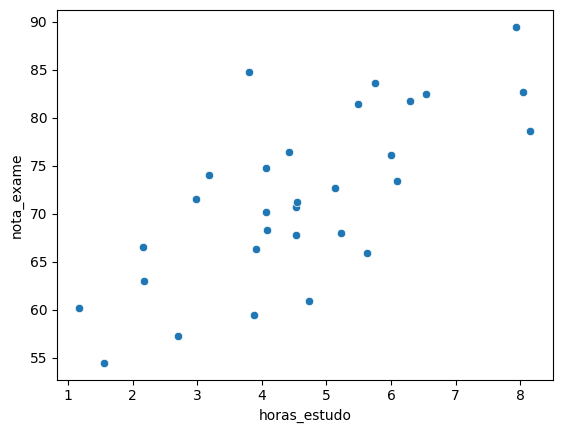

In [8]:
sns.scatterplot(df, x='horas_estudo', y='nota_exame')

<Axes: xlabel='horas_estudo', ylabel='aulas_participadas'>

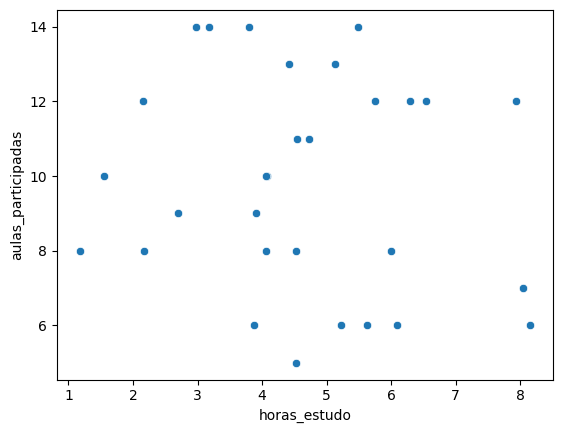

In [9]:
sns.scatterplot(df, x='horas_estudo', y='aulas_participadas')

<Axes: xlabel='horas_estudo', ylabel='sono_medio'>

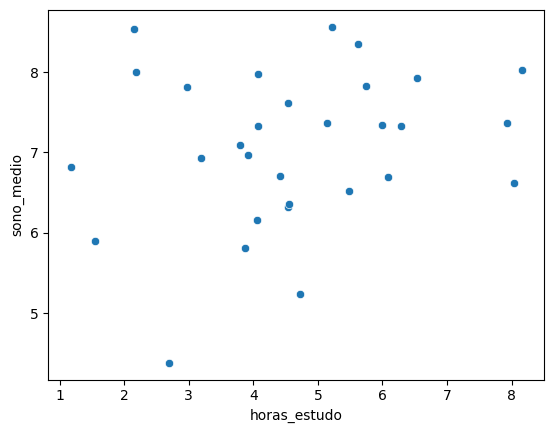

In [10]:
sns.scatterplot(df, x='horas_estudo', y='sono_medio')

<Axes: >

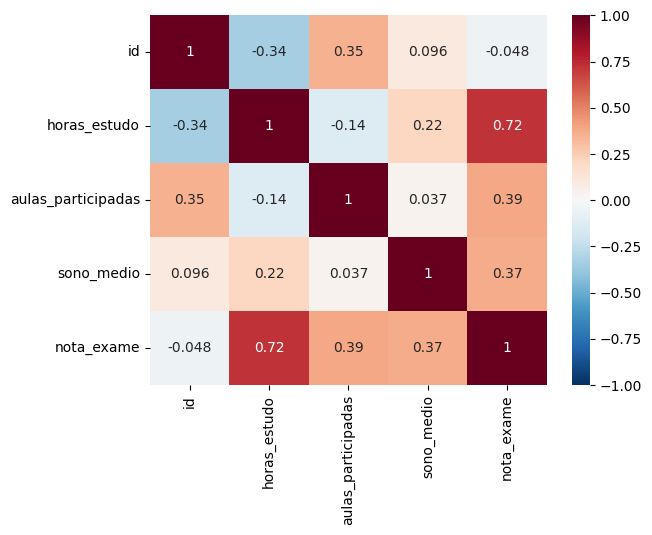

In [11]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    #cmap= 'RdBu',
    #cmap= 'viridis',
    cmap= 'RdBu_r',
    annot=True
    )

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  30 non-null     int64  
 1   horas_estudo        30 non-null     float64
 2   aulas_participadas  30 non-null     int64  
 3   sono_medio          30 non-null     float64
 4   nota_exame          30 non-null     float64
dtypes: float64(3), int64(2)
memory usage: 1.3 KB


In [13]:
y = df['horas_estudo']

df['intercepto'] = 1
x = df[['nota_exame', 'sono_medio','intercepto']]

In [14]:
modelo = sm.OLS(y,x)

In [15]:
resultado = modelo.fit()

In [16]:
print(resultado.summary())
#Porcentagem = 72%
#nota_exame = 0.15 - 0.18
#intercepto = -5.8768 - -5.6172
#sono_medio = -0.11

                            OLS Regression Results                            
Dep. Variable:           horas_estudo   R-squared:                       0.523
Model:                            OLS   Adj. R-squared:                  0.488
Method:                 Least Squares   F-statistic:                     14.81
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           4.56e-05
Time:                        19:57:43   Log-Likelihood:                -48.587
No. Observations:                  30   AIC:                             103.2
Df Residuals:                      27   BIC:                             107.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
nota_exame     0.1507      0.029      5.194      0.0

In [17]:
df['nova_nota'] = df['nota_exame'] * 0.15 + -5.88 + df['aulas_participadas'] * -0.31 + df['sono_medio'] * -0.11
display(df[['nota_exame','nova_nota']])

,nota_exame,nova_nota
0,76.119754,2.250165
1,60.929961,-0.726571
2,81.731317,1.854048
3,82.699637,3.627305
4,70.662399,2.473821
5,67.758906,0.966551
6,78.653234,3.174575
7,82.493253,1.901547
8,70.142780,1.483731
9,73.365811,2.528885
